# Multi Query

**이 노트북에서 할 일**

1. Ch 12에서 쓰던 문서 열두 건과 질문 여덟 개를 그대로 읽습니다.
2. 질문 하나를 한 번만 검색해 정답 문서의 자리를 셉니다.
3. 같은 질문을 변형 질문 세 개로 늘려 각각 검색합니다.
4. 네 목록을 Ch 12 순위 합치기로 하나로 만들어 자리를 다시 셉니다.
5. 질문만 바꾸어 같은 일을 다시 하고 두 결과를 견줍니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
서비스 요청은 열한 번입니다(임베딩 아홉 번과 답 모델 두 번).
예상 비용은 미화 0.01달러 아래입니다.
읽어 오는 파일은 이 챕터 폴더의 문서 파일과 질문 파일 둘이고 새로 쓰는 파일은 없습니다.
실행 시간은 2분 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3절부터 7절까지 읽습니다.
Ch 12 검색 부품과 순위 합치기 부품을 준비하고 질문 하나를 한 번 검색하는 자리입니다.
8절과 9절은 변형 질문을 만들고 목록 넷을 모으는 자리입니다.
10절부터 12절은 목록을 합치고 질문을 바꾸어 다시 재는 자리입니다.

실습 폴더 `labs/part4/ch14-rag-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

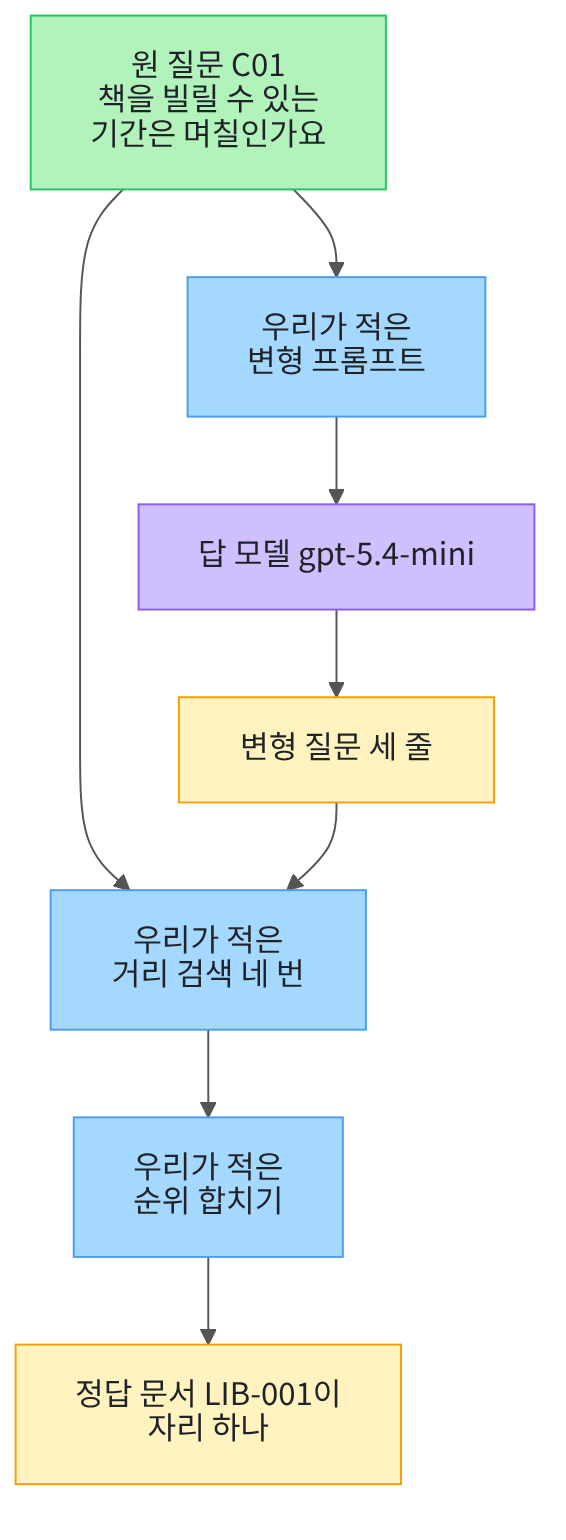

위에서 아래로 읽습니다.
맨 위 초록 상자가 사람이 적은 원 질문입니다.
가운데 파란 상자 셋이 우리가 적은 글과 처리이고 보라 상자가 모델입니다.
맨 아래 노란 상자 둘이 출력으로 확인한 값입니다.

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
이 노트북의 출력은 2026-09-19에 이 판으로 실행한 결과입니다.

다음 셀은 이름 다섯 개를 불러옵니다.
앞의 셋은 자료 읽기와 제곱근과 폴더 확인에 씁니다.
뒤의 둘은 Ch 9~13에서 쓴 임베딩과 답 모델 이름입니다.

In [2]:
# 자료 읽기·제곱근·경로 확인과 임베딩·답 모델 이름을 불러옵니다
import json
import math
import os

from langchain_openai import OpenAIEmbeddings
from langchain.chat_models import init_chat_model

print("불러온 이름:", "json", "math", "os", "OpenAIEmbeddings", "init_chat_model")

불러온 이름: json math os OpenAIEmbeddings init_chat_model


**결과 읽기** — 출력 줄에 불러온 이름 다섯 개가 보입니다.
이름 `OpenAIEmbeddings`와 `init_chat_model`은 01절에서 쓴 것과 같습니다.

## 2. 키와 모델 준비

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-19에 이 모델로 실행한 결과입니다.

## 3. 문서와 질문 읽기

이 절은 01절과 같은 문서 파일과 질문 파일을 읽습니다.
두 파일은 Ch 12 core 벌 파일과 바이트가 같은 사본입니다.
먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch14-rag-patterns/data"):
        root_path = candidate
        break
print("고른 자리:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 자리: .


**결과 읽기** — 출력 줄 `고른 자리` 뒤에 점 하나나 위로 올라가는 표시가 보입니다.
Ch 10~13과 01절에서 쓴 코드와 같습니다.
후보 셋 가운데 이 챕터 자료 폴더가 있는 자리를 고릅니다.

다음 셀은 문서 파일과 질문 파일을 읽습니다.

In [6]:
# 이 챕터 폴더의 문서 파일과 질문 파일을 읽습니다(읽기만 하고 고치지 않습니다)
data_path = root_path + "/labs/part4/ch14-rag-patterns/data"
with open(data_path + "/documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — 출력 줄 `문서 수: 12`와 `질문 수: 8`이 Ch 12 core 벌 그대로입니다.
문서는 도서관 안내 열두 건입니다.

질문 번호는 C01부터 C08까지이고 질문 파일에 적혀 있습니다.
이 절은 그 가운데 둘을 씁니다.

## 4. 이 절에서 쓸 값 정하기

Ch 12와 01절에서 정한 값을 그대로 다시 적습니다.
늘릴 변형 질문 개수도 여기서 못 박아 둡니다.

In [7]:
# Ch 12에서 쓴 값을 그대로 다시 정하고 늘릴 질문 개수도 못 박습니다
similarity_top = 1
top_three = 3
top_all = 12
variant_count = 3
print("코사인 유사도의 가장 큰 값:", similarity_top)
print("나란히 볼 상위 문서 수:", top_three)
print("자리를 셀 때 재는 문서 수:", top_all)
print("만들 변형 질문 수:", variant_count)

코사인 유사도의 가장 큰 값: 1
나란히 볼 상위 문서 수: 3
자리를 셀 때 재는 문서 수: 12
만들 변형 질문 수: 3


**결과 읽기** — 출력 줄 `코사인 유사도의 가장 큰 값: 1`은 Ch 12 01절에서 정한 값입니다.
출력 줄 `나란히 볼 상위 문서 수: 3`은 표로 볼 자리 수입니다.
출력 줄 `자리를 셀 때 재는 문서 수: 12`는 정답 자리를 끝까지 세려고 둔 값입니다.
출력 줄 `만들 변형 질문 수: 3`은 이 절이 늘릴 질문 개수입니다.

개수를 값으로 적어 두면 늘어난 요청 수를 셀 수 있습니다.
변형 질문 하나마다 임베딩 요청이 한 번씩 늘어납니다.

## 5. Ch 12 검색 부품 준비

다음 다섯 셀은 01절에서 이미 읽은 코드입니다.
읽지 말고 실행만 하고 넘어가도 됩니다.
문서 글을 이어 붙이고 거리 함수 네 개와 순위 함수 하나를 다시 정의합니다.
문서 ID를 모으는 함수와 정답 자리를 세는 함수와 출력 함수도 함께 준비합니다.

In [8]:
# 문서 12개의 제목과 본문을 이어 붙이고 문서 ID 목록도 만듭니다(Ch 12 06절과 같은 코드)
doc_texts = []
doc_ids = []
for doc in docs:
    doc_texts.append(doc["title"] + " " + doc["text"])
    doc_ids.append(doc["doc_id"])
print("이어 붙인 글 수:", len(doc_texts))
print("첫 문서 글:", doc_texts[0])
print("문서 ID 목록:")
print(doc_ids)

이어 붙인 글 수: 12
첫 문서 글: 도서 대출 기간 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.
문서 ID 목록:
['LIB-001', 'LIB-002', 'LIB-003', 'LIB-004', 'FAC-001', 'FAC-002', 'FAC-003', 'FAC-004', 'ACC-001', 'ACC-002', 'ACC-003', 'ACC-004']


In [9]:
# Ch 12 01절 점곱·길이·코사인 유사도·코사인 거리를 같은 코드로 다시 정의합니다
def dot_product(first, second):
    total = 0
    # 반복 번호 i로 두 벡터의 같은 자리 숫자를 짝지어 곱하고 더합니다
    for i in range(len(first)):
        total = total + first[i] * second[i]
    return total


def vector_length(vector):
    squared_sum = dot_product(vector, vector)
    return math.sqrt(squared_sum)


def cosine_similarity(first, second):
    dot = dot_product(first, second)
    length_product = vector_length(first) * vector_length(second)
    return dot / length_product


def cosine_distance(first, second):
    similarity = cosine_similarity(first, second)
    return similarity_top - similarity

In [10]:
# Ch 12 05절 거리 순위 만들기를 같은 코드로 다시 정의합니다
def rank_by_distance(question_vector, top_count):
    pairs = []
    for i in range(len(doc_ids)):
        distance = cosine_distance(question_vector, doc_vectors[i])
        pairs.append((distance, doc_ids[i]))
    hit_list = []
    # sorted(목록)는 튜플의 첫 값인 거리를 작은 값부터 정렬합니다
    for pair in sorted(pairs):
        hit_list.append({"doc_id": pair[1], "거리": round(pair[0], 2)})
    return hit_list[:top_count]

In [11]:
# Ch 11 01절 문서 ID 모으기와 정답 자리 세기를 같은 코드로 다시 정의합니다
def unique_doc_ids(hit_list):
    doc_ids = []
    for hit in hit_list:
        if hit["doc_id"] not in doc_ids:
            doc_ids.append(hit["doc_id"])
    return doc_ids


def find_gold_rank(doc_ids, gold_doc_ids):
    gold_rank = 0
    for position in range(len(doc_ids)):
        if doc_ids[position] in gold_doc_ids:
            gold_rank = position + 1
            break
    return gold_rank

In [12]:
# Ch 12 05절 순위 목록 출력 함수를 같은 코드로 다시 정의합니다
def print_ranked(hit_list, value_name):
    print("순위 | 문서 ID |", value_name)
    for rank_number in range(len(hit_list)):
        row = hit_list[rank_number]
        print(rank_number + 1, "|", row["doc_id"], "|", row[value_name])

준비 셀 다섯 개를 지났습니다.
다음 셀은 문서 열두 건을 벡터로 바꿉니다.
이 절에서 서비스에 보내는 첫 요청입니다.

In [13]:
# Ch 12와 같은 모델로 문서 12개를 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
doc_vectors = embedding_model.embed_documents(doc_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 벡터 수:", len(doc_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 벡터 수: 12


**결과 읽기** — 출력 줄 `임베딩 모델 이름: text-embedding-3-small`은 01절과 같은 모델입니다.
출력 줄 `벡터의 숫자 개수 설정: 256`도 Ch 10~13과 같은 값입니다.
출력 줄 `문서 벡터 수: 12`로 문서마다 벡터 하나를 받았습니다.
벡터 안의 숫자는 호출마다 아주 조금씩 달라져 소수 자리까지 같다고 보지 않습니다.

## 6. 순위 합치기 부품 준비

이 절은 순위 목록 네 개를 하나로 만들어야 합니다.
그 일은 Ch 12 06절에서 「순위 합치기」로 배웠습니다.
먼저 자리 번호를 몫으로 바꾸는 식에 쓸 값 두 개를 정합니다.

In [14]:
# 자리 번호를 몫으로 바꾸는 식에 쓸 값을 정하고 앞자리 세 곳의 몫을 봅니다
rank_constant = 60
base_weight = 1.0
print("순위 상수:", rank_constant)
print("목록 하나에 줄 가중치:", base_weight)
print("자리 | 기본 가중치가 주는 몫")
for position in range(top_three):
    share = base_weight / (rank_constant + position + 1)
    print(position + 1, "|", round(share, 4))

순위 상수: 60
목록 하나에 줄 가중치: 1.0
자리 | 기본 가중치가 주는 몫
1 | 0.0164
2 | 0.0161
3 | 0.0159


**결과 읽기** — 출력 줄 `순위 상수: 60`은 Ch 12 06절에서 정한 값 그대로입니다.
출력 줄 `목록 하나에 줄 가중치: 1.0`으로 네 목록을 같은 크기로 봅니다.
라벨 줄 `자리 | 기본 가중치가 주는 몫` 아래 세 줄에 앞자리 몫이 있습니다.
첫 자리가 받는 몫은 `0.0164`이고 셋째 자리는 `0.0159`입니다.

앞자리일수록 나누는 수가 작아 몫이 큽니다.
여러 목록에서 고르게 앞자리에 있는 문서가 몫을 많이 모읍니다.

다음 두 셀은 Ch 12 06절 함수 두 개를 같은 코드로 다시 정의합니다.

In [15]:
# 순위 목록 여러 개를 받아 문서마다 자리 몫을 더한 합친 점수를 냅니다
def fuse_scores(ranking_list, weight_list):
    scores = {}
    for list_index in range(len(ranking_list)):
        ranking = ranking_list[list_index]
        weight = weight_list[list_index]
        # 자리 번호는 1부터 세고 앞자리일수록 나누는 수가 작아 몫이 큽니다
        for position in range(len(ranking)):
            doc_id = ranking[position]
            share = weight / (rank_constant + position + 1)
            scores[doc_id] = scores.get(doc_id, 0.0) + share
    return scores

In [16]:
# 합친 점수가 큰 순서로 문서 ID 목록을 만듭니다(Ch 12 04~06절과 같은 음수 붙이기)
def fuse_rank(ranking_list, weight_list):
    scores = fuse_scores(ranking_list, weight_list)
    pairs = []
    for doc_id in scores:
        # 점수에 음수를 붙이면 sorted가 큰 점수를 앞으로 보냅니다
        pairs.append((0 - scores[doc_id], doc_id))
    fused_ids = []
    for pair in sorted(pairs):
        fused_ids.append(pair[1])
    return fused_ids

준비가 끝났습니다.
함수 `fuse_scores`는 목록마다 자리 몫을 더해 문서별 합친 점수를 냅니다.
함수 `fuse_rank`는 그 점수가 큰 순서로 문서 ID 목록을 만듭니다.

## 7. 질문 하나로 한 번 검색하기

먼저 질문 하나를 그대로 검색해 기준이 될 자리를 잽니다.
01절이 Ch 12 05절과 대조할 때 쓴 첫 질문을 그대로 고릅니다.

In [17]:
# 01절이 Ch 12와 대조할 때 쓴 첫 질문을 그대로 골라 정답 문서 ID도 적어 둡니다
base_query = queries[0]
base_question = base_query["question"]
gold_doc_id = base_query["gold_doc_id"]
print("고른 질문:", base_query["qid"], "|", base_question)
print("그 질문의 정답 문서 ID:", gold_doc_id)

고른 질문: C01 | 책을 빌릴 수 있는 기간은 며칠인가요?
그 질문의 정답 문서 ID: LIB-001


**결과 읽기** — 출력 줄 `고른 질문: C01` 뒤에 질문 한 줄이 있습니다.
출력 줄 `그 질문의 정답 문서 ID: LIB-001`은 자료 파일에 적힌 정답입니다.

실행 전에 예상해 봅니다.
질문에 「빌릴 수 있는 기간」이 있으니 대출을 다룬 문서가 앞으로 올 것입니다.

In [18]:
# 고른 질문을 한 번만 검색해 앞 세 자리와 정답 문서의 자리를 봅니다(임베딩 요청 1번)
base_vector = embedding_model.embed_query(base_question)
base_hits = rank_by_distance(base_vector, top_all)
base_ids = unique_doc_ids(base_hits)
base_place = find_gold_rank(base_ids, [gold_doc_id])
print_ranked(base_hits[:top_three], "거리")
print("한 번만 검색했을 때 정답 문서의 자리:", base_place)

순위 | 문서 ID | 거리
1 | LIB-004 | 0.43
2 | LIB-001 | 0.56
3 | LIB-003 | 0.62
한 번만 검색했을 때 정답 문서의 자리: 2


**결과 읽기** — 순위 표의 차례는 `LIB-004`와 `LIB-001`과 `LIB-003`입니다.
01절이 Ch 12 05절과 대조한 표와 같습니다.
출력 줄 `한 번만 검색했을 때 정답 문서의 자리: 2`로 정답 문서는 둘째 자리였습니다.
전자책 문서가 첫 자리에 오고 일반 도서 대출 문서가 그 뒤에 왔습니다.

거리 값은 소수 둘째 자리까지만 읽습니다.
셋째 자리 아래는 호출마다 조금씩 달라져 본문과 그림에 넣지 않았습니다.

## 8. 변형 질문 만들기

같은 것을 묻는 질문을 표현만 달리해 세 줄 더 만듭니다.
머리글에 개수와 모양을 적어 한 줄에 질문 하나만 오게 합니다.
대상과 조건을 그대로 두라는 줄도 함께 넣습니다.

In [19]:
# 머리글 세 줄과 원 질문을 한 글로 이어 붙입니다
def build_variant_prompt(question):
    variant_head = "아래 질문과 같은 것을 묻되 표현과 관점을 달리한 검색 질문을 "
    variant_head = variant_head + str(variant_count) + "줄 적으세요.\n"
    variant_head = variant_head + "한 줄에 질문 하나만 적고 번호나 기호를 붙이지 마세요.\n"
    variant_head = variant_head + "질문이 가리키는 대상과 조건은 그대로 두세요.\n\n"
    prompt_text = variant_head + "질문: " + question
    return prompt_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_variant_prompt`는 머리글 세 줄을 이어 붙인 뒤 원 질문을 답니다.
머리글의 개수 자리에는 앞에서 정한 값 `variant_count`가 들어갑니다.
값을 바꾸면 머리글과 실제로 쓰는 개수가 함께 바뀝니다.

다음 셀은 그 글을 만들어 모델에 넣습니다.

In [20]:
# 만든 글을 모델에 넣어 변형 질문을 받습니다(모델 요청 1번)
variant_prompt = build_variant_prompt(base_question)
print("모델에 넣을 글:")
print(variant_prompt)
variant_reply = model.invoke(variant_prompt)
variant_text = variant_reply.text.strip()
print("모델이 쓴 글:")
print(variant_text)

모델에 넣을 글:
아래 질문과 같은 것을 묻되 표현과 관점을 달리한 검색 질문을 3줄 적으세요.
한 줄에 질문 하나만 적고 번호나 기호를 붙이지 마세요.
질문이 가리키는 대상과 조건은 그대로 두세요.

질문: 책을 빌릴 수 있는 기간은 며칠인가요?


모델이 쓴 글:
책 대출 기간은 보통 며칠로 정해져 있나요?
도서관에서 책을 빌리면 몇 일 동안 보관할 수 있나요?
책을 대여할 때 이용 가능한 기간이 며칠인지 알고 싶어요.


**결과 읽기** — 라벨 줄 `모델에 넣을 글:` 아래에 머리글 세 줄과 원 질문이 있습니다.
라벨 줄 `모델이 쓴 글:` 아래에는 질문 세 줄이 있습니다.
세 줄 모두 빌리는 기간을 묻고 표현만 다릅니다.
문장은 실행마다 달라질 수 있어 이 값에 `assert`를 걸지 않았습니다.

## 9. 변형 질문마다 검색하기

모델이 보낸 글은 줄 하나가 질문 하나입니다.
줄로 나눌 때 글자를 깎지 않고 빈 줄만 뺍니다.
먼저 그 일을 하는 함수를 만듭니다.

In [21]:
# 글을 줄로 나누고 빈 줄을 뺀 목록을 만듭니다
def split_lines(reply_text):
    lines = []
    for line in reply_text.split("\n"):
        clean_line = line.strip()
        if clean_line != "":
            lines.append(clean_line)
    return lines

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `split_lines`는 글을 줄 단위로 나눈 뒤 빈 줄을 뺀 목록을 만듭니다.
줄 앞뒤 공백만 없애고 글자는 그대로 둡니다.

다음 셀은 그 목록에서 앞의 세 줄만 고릅니다.

In [22]:
# 모델이 보낸 글을 줄로 나누고 앞에서 정한 개수만 골라 씁니다
variant_lines = split_lines(variant_text)
variants = variant_lines[:variant_count]
print("모델이 보낸 줄 수:", len(variant_lines))
print("쓸 변형 질문 수:", len(variants))
for variant in variants:
    print("변형 질문:", variant)

모델이 보낸 줄 수: 3
쓸 변형 질문 수: 3
변형 질문: 책 대출 기간은 보통 며칠로 정해져 있나요?
변형 질문: 도서관에서 책을 빌리면 몇 일 동안 보관할 수 있나요?
변형 질문: 책을 대여할 때 이용 가능한 기간이 며칠인지 알고 싶어요.


**결과 읽기** — 출력 줄 `모델이 보낸 줄 수: 3`으로 세 줄이 왔습니다.
출력 줄 `쓸 변형 질문 수: 3`은 앞에서 정한 개수와 같습니다.
라벨 줄 `변형 질문:` 세 줄에 실제로 쓸 질문이 있습니다.
받은 줄이 더 많아도 앞의 세 줄만 씁니다.

적게 오면 온 만큼만 씁니다.
그때는 `쓸 변형 질문 수`가 `만들 변형 질문 수`보다 작게 나옵니다.

다음 셀은 검색 한 번을 함수 하나로 묶습니다.

In [23]:
# 질문 하나를 벡터로 바꿔 문서 ID 순위 목록을 만듭니다(부를 때마다 임베딩 요청 1번)
def search_ids(question):
    question_vector = embedding_model.embed_query(question)
    hit_list = rank_by_distance(question_vector, top_all)
    found_ids = unique_doc_ids(hit_list)
    return found_ids

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `search_ids`는 질문 하나를 벡터로 바꾸고 문서 ID 순위 목록을 만듭니다.
부를 때마다 임베딩 요청이 한 번씩 갑니다.
자리를 끝까지 세려고 문서 열두 건을 모두 담습니다.

다음 셀은 원 질문 목록 뒤에 변형 질문 목록 셋을 붙입니다.

In [24]:
# 원 질문 목록 뒤에 변형 질문 목록 셋을 이어 붙입니다(임베딩 요청 3번)
ranking_list = []
ranking_list.append(base_ids)
for variant in variants:
    ranking_list.append(search_ids(variant))
print("합칠 목록 수:", len(ranking_list))
print("첫 자리 문서 | 정답 문서의 자리")
for found_ids in ranking_list:
    print(found_ids[0], "|", find_gold_rank(found_ids, [gold_doc_id]))

합칠 목록 수: 4
첫 자리 문서 | 정답 문서의 자리
LIB-004 | 2
LIB-001 | 1
LIB-001 | 1
LIB-004 | 2


**결과 읽기** — 출력 줄 `합칠 목록 수: 4`로 목록이 넷입니다.
라벨 줄 `첫 자리 문서 | 정답 문서의 자리` 아래 네 줄이 있습니다.
첫 줄은 원 질문이고 첫 자리 문서가 `LIB-004`이며 정답 자리가 `2`입니다.
아래 세 줄은 변형 질문이고 그 가운데 둘은 첫 자리 문서가 `LIB-001`입니다.

변형 질문 문장은 실행마다 달라질 수 있습니다.
문장이 달라지면 이 표의 자리도 함께 달라집니다.
그래서 목록별 자리는 본문 결론에 넣지 않았습니다.

## 10. 네 목록을 하나로 합치기

이제 목록 넷을 순위 합치기로 하나로 만듭니다.
목록마다 같은 가중치를 주어 어느 한 갈래에 치우치지 않게 합니다.

In [25]:
# 목록마다 같은 가중치를 주고 자리 몫을 더해 하나로 합칩니다
weight_list = []
for found_ids in ranking_list:
    weight_list.append(base_weight)
fused_ids = fuse_rank(ranking_list, weight_list)
fused_place = find_gold_rank(fused_ids, [gold_doc_id])
print("쓴 가중치:", weight_list)
print("합친 목록의 앞 세 자리:", fused_ids[:top_three])
print("합친 뒤 정답 문서의 자리:", fused_place)

쓴 가중치: [1.0, 1.0, 1.0, 1.0]
합친 목록의 앞 세 자리: ['LIB-001', 'LIB-004', 'LIB-003']
합친 뒤 정답 문서의 자리: 1


**결과 읽기** — 출력 줄 `쓴 가중치: [1.0, 1.0, 1.0, 1.0]`으로 네 목록을 같게 봤습니다.
출력 줄 `합친 목록의 앞 세 자리`의 맨 앞은 `LIB-001`입니다.
출력 줄 `합친 뒤 정답 문서의 자리: 1`로 정답 문서가 첫 자리로 왔습니다.
한 번만 검색했을 때의 둘째 자리에서 한 자리 올라왔습니다.

합친 목록의 앞 세 자리는 새 커널로 두 번 실행했을 때 같았습니다.
변형 질문 문장이 달라지면 뒷자리는 달라질 수 있습니다.

## 11. 값 바꿔 보기 · 질문을 바꾸기

바꿀 값은 검색에 쓸 질문 하나입니다.
머리글도 변형 개수도 가중치도 그대로 두고 질문만 `C02`로 바꿉니다.
실행 전에 예상해 봅니다.
질문에 「돈」이 있고 문서에는 그 말이 없어 정답 문서가 뒤로 밀릴 것입니다.

In [26]:
# 바꿀 값은 검색에 쓸 질문 하나입니다(임베딩 요청 1번)
second_query = queries[1]
second_question = second_query["question"]
second_gold = second_query["gold_doc_id"]
second_ids = search_ids(second_question)
second_place = find_gold_rank(second_ids, [second_gold])
print("바꾼 질문:", second_query["qid"], "|", second_question)
print("그 질문의 정답 문서 ID:", second_gold)
print("한 번만 검색했을 때 정답 문서의 자리:", second_place)

바꾼 질문: C02 | 책을 늦게 반납하면 돈을 내나요?
그 질문의 정답 문서 ID: LIB-002
한 번만 검색했을 때 정답 문서의 자리: 7


**결과 읽기** — 출력 줄 `바꾼 질문: C02` 뒤에 질문 한 줄이 있습니다.
출력 줄 `그 질문의 정답 문서 ID: LIB-002`는 연체를 다룬 문서입니다.
출력 줄 `한 번만 검색했을 때 정답 문서의 자리: 7`로 일곱째 자리였습니다.
질문의 말과 문서의 말이 멀어 앞자리에 오지 못했습니다.

다음 셀은 같은 머리글로 변형 질문을 다시 받습니다.

In [27]:
# 바꾼 질문으로 같은 머리글을 써서 변형 질문을 받습니다(모델 요청 1번)
second_prompt = build_variant_prompt(second_question)
second_reply = model.invoke(second_prompt)
second_text = second_reply.text.strip()
second_lines = split_lines(second_text)
second_variants = second_lines[:variant_count]
print("모델이 보낸 줄 수:", len(second_lines))
for variant in second_variants:
    print("변형 질문:", variant)

모델이 보낸 줄 수: 3
변형 질문: 도서관 책을 반납 기한을 넘기면 연체료가 부과되나요?
변형 질문: 책 반납일을 지나서 돌려주면 벌금을 내야 하나요?
변형 질문: 대출한 책을 늦게 반납했을 때 추가 비용이 발생하나요?


**결과 읽기** — 출력 줄 `모델이 보낸 줄 수: 3`으로 이번에도 세 줄이 왔습니다.
라벨 줄 `변형 질문:` 세 줄에 연체료와 벌금과 추가 비용을 묻는 질문이 있습니다.
문장은 실행마다 달라집니다.

다음 셀은 목록 넷을 모아 앞에서 쓴 가중치 그대로 합칩니다.

In [28]:
# 바꾼 질문도 목록 넷을 모아 앞에서 쓴 가중치 그대로 합칩니다(임베딩 요청 3번)
second_ranking_list = []
second_ranking_list.append(second_ids)
for variant in second_variants:
    second_ranking_list.append(search_ids(variant))
second_fused = fuse_rank(second_ranking_list, weight_list)
second_fused_place = find_gold_rank(second_fused, [second_gold])
print("첫 자리 문서 | 정답 문서의 자리")
for found_ids in second_ranking_list:
    print(found_ids[0], "|", find_gold_rank(found_ids, [second_gold]))
print("합친 뒤 정답 문서의 자리:", second_fused_place)

첫 자리 문서 | 정답 문서의 자리
LIB-003 | 7
LIB-002 | 1
LIB-003 | 5
LIB-001 | 6
합친 뒤 정답 문서의 자리: 4


**결과 읽기** — 라벨 줄 `첫 자리 문서 | 정답 문서의 자리` 아래 네 줄이 있습니다.
네 줄 가운데 한 줄만 정답 문서를 첫 자리에 두었습니다.
출력 줄 `합친 뒤 정답 문서의 자리: 4`로 넷째 자리에 그쳤습니다.
자리는 일곱에서 넷으로 올라왔지만 앞 세 자리 안에는 들지 못했습니다.

순위 합치기는 여러 목록에서 고르게 앞자리인 문서를 위로 올립니다.
한 목록에서만 앞자리인 문서는 몫을 한 번밖에 모으지 못합니다.
목록별 첫 자리 문서는 실행마다 달라져 결론에 넣지 않았습니다.

## 12. 네 실행을 기록 한 줄씩으로

실행 하나를 기록 한 줄로 만들어 담아 둡니다.
Ch 9~13과 01절에서 쓴 기록 한 줄과 같은 모양입니다.

In [29]:
# 실행 한 번을 기록 한 줄로 만듭니다
def run_row(run_name, question_text, found_ids, place):
    row = {"실행": run_name}
    row["검색에 쓴 질문"] = question_text
    row["첫 자리 문서"] = found_ids[0]
    row["정답 자리"] = place
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
담는 칸은 실행 이름과 검색에 쓴 질문과 첫 자리 문서와 정답 자리 넷입니다.
이 절이 견주는 값이 그 넷이기 때문입니다.

다음 셀은 네 실행의 기록을 표로 출력합니다.

In [30]:
# 네 실행의 기록을 담아 라벨 줄 아래에 한 줄씩 출력합니다
run_rows = []
run_rows.append(run_row("C01 한 번 검색", base_question, base_ids, base_place))
run_rows.append(run_row("C01 합친 목록", base_question, fused_ids, fused_place))
run_rows.append(run_row("C02 한 번 검색", second_question, second_ids, second_place))
run_rows.append(run_row("C02 합친 목록", second_question, second_fused, second_fused_place))
print("실행 | 검색에 쓴 질문 | 첫 자리 문서 | 정답 자리")
for row in run_rows:
    print(row["실행"], "|", row["검색에 쓴 질문"], "|", row["첫 자리 문서"], "|", row["정답 자리"])

실행 | 검색에 쓴 질문 | 첫 자리 문서 | 정답 자리
C01 한 번 검색 | 책을 빌릴 수 있는 기간은 며칠인가요? | LIB-004 | 2
C01 합친 목록 | 책을 빌릴 수 있는 기간은 며칠인가요? | LIB-001 | 1
C02 한 번 검색 | 책을 늦게 반납하면 돈을 내나요? | LIB-003 | 7
C02 합친 목록 | 책을 늦게 반납하면 돈을 내나요? | LIB-003 | 4


**결과 읽기** — 라벨 줄 `실행 | 검색에 쓴 질문 | 첫 자리 문서 | 정답 자리` 아래 네 줄이 나옵니다.
질문 `C01`은 합친 뒤 정답 자리가 `1`로 올라왔습니다.
질문 `C02`는 합친 뒤에도 정답 자리가 `4`였습니다.
같은 방법을 써도 질문에 따라 결과가 달랐습니다.

## 정리

1. 질문 하나만으로 검색하니 질문 `C01`의 정답 문서는 둘째 자리였습니다.
2. 변형 질문 셋을 더해 네 목록을 합치니 정답 문서가 첫 자리로 왔습니다.
3. 질문 `C02`에서는 같은 방법을 써도 정답 문서가 앞 세 자리 안에 들지 못했습니다.

03절에서는 한 질문 안에 섞인 여러 사실을 하위 질문으로 나눕니다.
이 절이 만든 변형 질문은 같은 것을 묻는 질문이고 03절은 다른 것을 묻는 질문을 만듭니다.